Index([1, 2, 3, 4, 17, 22, 27], dtype='object')


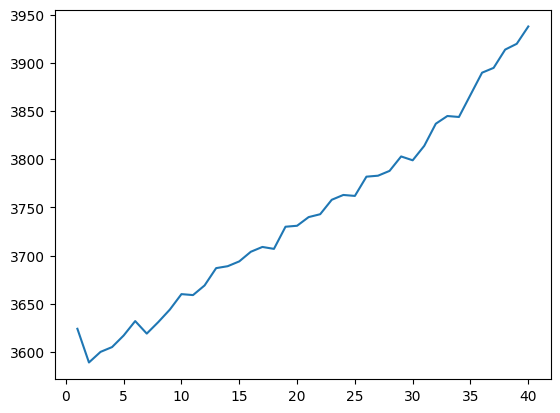

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

file_name = "data/qPCR_example.xlsx"
sheet_name = "시트1"

input_data = pd.read_excel(file_name, sheet_name=sheet_name)
df = input_data.set_index("X")
df_cq = df.apply(pd.to_numeric, errors="coerce")
print(df_cq.columns)

plt.plot(df_cq.index, df_cq[27])

In [33]:
# anomaly detection test
from src.pcr_anomaly_detector import PCRAnomalyDetector
import matplotlib.pyplot as plt


normal_rfu = [
    9655,
    9719,
    9670,
    9708,
    9668,
    9630,
    9665,
    9667,
    9555,
    9590,
    9515,
    9468,
    9519,
    9468,
    9437,
    9444,
    9408,
    9393,
    9370,
    9404,
    9372,
    9347,
    9310,
    9387,
    9382,
    9408,
    9523,
    9553,
    9829,
    10079,
    10518,
    10988,
    11504,
    12030,
    12433,
    12994,
    13485,
    13930,
    14387,
    14847,
    15253,
    15701,
    16099,
    16471,
]

In [34]:
def get_normalized_rfu_primitive(rfu):
    rfu_baseline_substracted = [rfu[i] - rfu[0] for i in range(len(rfu))]
    rfu_normalized = [rfu_baseline_substracted[i] / rfu[0] for i in range(len(rfu))]
    return rfu_normalized

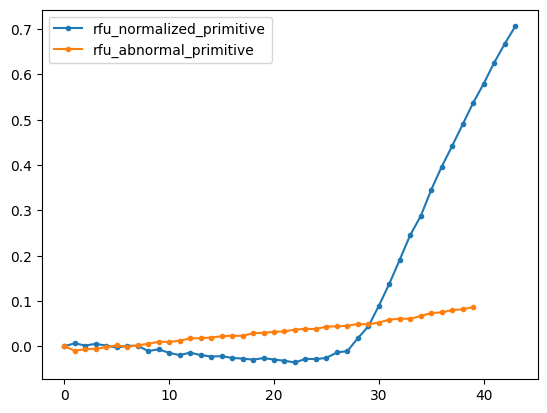

In [35]:
detector = PCRAnomalyDetector(seq_len=3)
detector.load_model("models/pcr_anomaly_detector_lstm_ws3.keras")

rfu_normalized_primitive = get_normalized_rfu_primitive(normal_rfu)
rfu_abnormal_primitive = get_normalized_rfu_primitive(df_cq[27].tolist())

plt.plot(rfu_normalized_primitive, ".-", label="rfu_normalized_primitive")
plt.plot(rfu_abnormal_primitive, ".-", label="rfu_abnormal_primitive")
plt.legend()

In [36]:
normal_output = detector.detect_anomaly(rfu_normalized_primitive, threshold=0.1)
detector.get_error(rfu_normalized_primitive)

[0.007201914590359475,
 0.009766654589211984,
 0.0015596319115390314,
 0.005899829422483044,
 0.005152609640301231,
 0.013643063654990965,
 0.013335786354720809,
 0.01304077960122502,
 0.0008471891091068676,
 0.008197260430783945,
 0.012381912787179143,
 8.403267470250692e-05,
 0.0019029596134642127,
 0.006426441718851698,
 7.204395819672416e-06,
 0.0029284541993360932,
 0.0037122079216094298,
 0.008798627026768806,
 0.0015475003476095942,
 0.003467505225735218,
 0.00944975630907368,
 0.010322079273902461,
 0.0009954988462575545,
 0.007216387622903383,
 0.010670570633313867,
 0.023404884276644423,
 0.005538903858178887,
 0.015101763368393709,
 0.00596110299422542,
 0.009622117471102282,
 0.01739756830117667,
 0.03204534912837842,
 0.0036936600118150364,
 0.017428164498167642,
 0.008868656770853356,
 0.004451328207334071,
 0.007033894878172076,
 0.002238136804640911,
 0.011090780996029226,
 8.807118108145051e-05,
 2.84491395283748e-05]

In [37]:
abnormal_output = detector.detect_anomaly(rfu_abnormal_primitive, threshold=0.1)
detector.get_error(rfu_abnormal_primitive)

[0.0033345232999351113,
 3.9379459869519394e-05,
 0.001027953808933957,
 0.009617052857186358,
 0.005076606410491809,
 0.0014542941883962934,
 0.0010419734661152816,
 0.0065789156270606095,
 0.0012662325868543402,
 0.0004787981904895086,
 0.006294855482004598,
 0.0009246037627424347,
 0.00027299111515743935,
 0.0031076763770964515,
 0.003624535027981858,
 0.005344707313226022,
 0.007926655789347935,
 0.0004942152015947054,
 0.003288329897600556,
 0.0017156957527396446,
 0.004511417668913109,
 0.0033217968530212805,
 0.004356025991587187,
 0.007055672193994583,
 0.0005027749154215069,
 0.0012817356496983567,
 0.006997462666324172,
 0.0038428411841655644,
 0.0005664284655589949,
 0.0062421775087878675,
 0.004249011575517804,
 0.0053281534389154755,
 0.001900866792165154,
 0.00722312210148271,
 0.0022427223902401344,
 0.005422444006728283,
 0.001752422970388634]

In [44]:
import numpy as np

# X: cycle values from 1 to 45
X = np.arange(1, 46)

# Parabola: minimum at X=15, open upwards
# f(X) = a*(X-15)^2 + c
a = 10  # scale factor for RFU range
c = 1000  # baseline RFU

rfu_parabola = a * (X - 15) ** 2 + c

parabolar_normalized_primitive = get_normalized_rfu_primitive(rfu_parabola.tolist())
parabolar_output = detector.detect_anomaly(
    parabolar_normalized_primitive, threshold=0.01
)
detector.get_error(parabolar_normalized_primitive)

[0.020346747862326153,
 0.02827216644544861,
 0.03097678036303131,
 0.029643205372062886,
 0.025717390550149433,
 0.020422005975568647,
 0.01460051697653697,
 0.008725707595412802,
 0.0029825906495790644,
 0.0026290126748986786,
 0.00819570792687907,
 0.013811134003304137,
 0.01951707376016154,
 0.025267393202395017,
 0.03090855076506327,
 0.03617923968547099,
 0.04072832900124623,
 0.044158196127092486,
 0.04609202049873973,
 0.04626670721414927,
 0.04462992339520844,
 0.041396424577042845,
 0.03699524499274587,
 0.03182710666914243,
 0.025804778208603732,
 0.017783552408218384,
 0.005427195413692576,
 0.012860058127222823,
 0.03257179904628443,
 0.04104561660740824,
 0.029589097242097573,
 0.006660110241658024,
 0.009622158230962019,
 0.01523099718867127,
 0.02287161350250244,
 0.02936469542013631,
 0.023936703398421022,
 0.020134461892617805,
 0.025662824914262083,
 0.03229754357724568,
 0.03607085588816039,
 0.038602339254843354]

In [45]:
print(parabolar_output)

[3, 4, 5, 6, 7, 8, 9, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 31, 32, 33, 36, 37, 38, 39, 40, 41, 42, 43, 44]


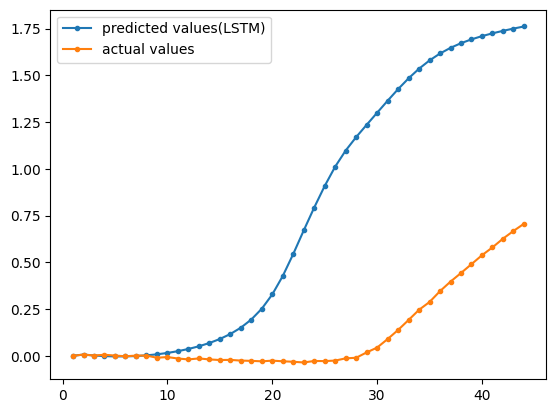

In [ ]:
## LSTM 예측 테스트

detector.load_model("models/pcr_anomaly_detector_lstm_ws3.keras")


def prediction(detector, rfu_normalized_primitive):
    y = rfu_normalized_primitive[:3]
    X = range(1, len(rfu_normalized_primitive) + 1)
    for i in range(len(X) - len(y)):
        seq = np.array(y[i : i + 3])
        next_val = detector.predict_next(seq)
        y.append(next_val)
    return y


# y = rfu_normalized_primitive[:3]
# X = range(1, len(rfu_normalized_primitive) + 1)
# for i in range(len(X) - len(y)):
#     seq = np.array(y[i : i + 3])
#     next_val = detector.predict_next(seq)
#     y.append(next_val)

y_lstm = prediction(detector, rfu_normalized_primitive)
detector.load_model("models/pcr_anomaly_detector_gru_ws3.keras")
y_gru = prediction(detector, rfu_normalized_primitive)
detector.load_model("models/pcr_anomaly_detector_simple_rnn_ws3.keras")
y_rnn = prediction(detector, rfu_normalized_primitive)
plt.plot(X, y_lstm, ".-", label="predicted values(LSTM)")
plt.plot(X, y_gru, ".-", label="predicted values(GRU)")
plt.plot(X, y_rnn, ".-", label="predicted values(SimpleRNN)")
plt.plot(X, rfu_normalized_primitive, ".-", label="actual values")
plt.legend()
plt.show()

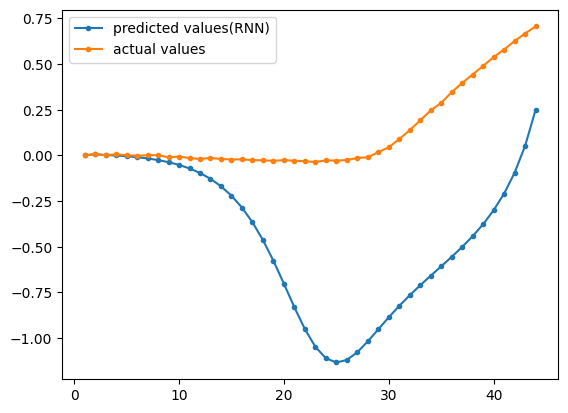

In [48]:
detector.load_model("models/pcr_anomaly_detector_rnn_ws3.keras")
y = rfu_normalized_primitive[:3]
X = range(1, len(rfu_normalized_primitive) + 1)
for i in range(len(X) - len(y)):
    seq = np.array(y[i : i + 3])
    next_val = detector.predict_next(seq)
    y.append(next_val)

plt.plot(X, y, ".-", label="predicted values(RNN)")
plt.plot(X, rfu_normalized_primitive, ".-", label="actual values")
plt.legend()
plt.show()

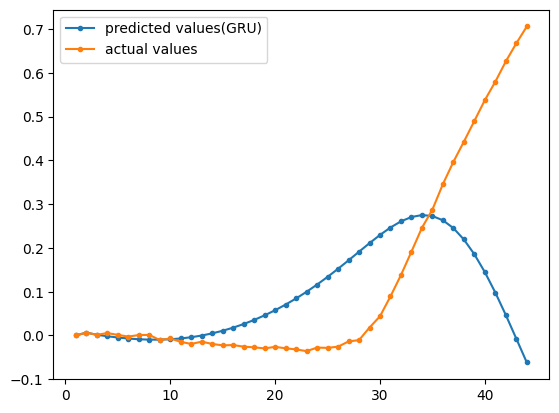

In [49]:
detector.load_model("models/pcr_anomaly_detector_gru_ws3.keras")
y = rfu_normalized_primitive[:3]
X = range(1, len(rfu_normalized_primitive) + 1)
for i in range(len(X) - len(y)):
    seq = np.array(y[i : i + 3])
    next_val = detector.predict_next(seq)
    y.append(next_val)

plt.plot(X, y, ".-", label="predicted values(GRU)")
plt.plot(X, rfu_normalized_primitive, ".-", label="actual values")
plt.legend()
plt.show()